# EKSPLORASI OPTUNA


# 1. SETUP

In [1]:
import copy
import gc
import os
import random
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

def seed_everything(seed) :
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed = 42
seed_everything(seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. CONFIG

In [2]:
SEEDS = [42, 43, 44] # default 42
DATA_DIR = Path("data/processed")
CHECKPOINT_DIR = Path("checkpoints")
REPORT_DIR = Path("reports")
FIG_DIR = REPORT_DIR / "figures"
METRICS_DIR = REPORT_DIR / "metrics"
for directory in (CHECKPOINT_DIR, FIG_DIR, METRICS_DIR) :
    directory.mkdir(parents=True, exist_ok=True)
assert DATA_DIR.is_dir(), f"Dataset terproses tidak ditemukan: {DATA_DIR}"

IMG_SIZE = (224, 224)
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
HIDDEN_DIM = 512
NUM_CLASSES = 4
STAGE_MAX_EPOCHS = 50
PATIENCE = 5
FINE_TUNE_LR_DIV = 10
BASE_CONFIG = {"optimizer": "Adam", "lr": 1e-4, "dropout": 0.5, "batch_size": 16}
GRID = {
    "optimizer": ["Adam", "AdamW"],
    "lr": [1e-3, 1e-4, 1e-5],
    "dropout": [0.2, 0.3, 0.4, 0.5],
    "batch_size": [16, 32],
}
CLASS_DISPLAY_NAMES = {
    "leaf_curl": "Leaf Curl",
    "leaf_spot": "Leaf Spot",
    "yellowish": "Yellowish",
    "healthy_leaf": "Healthy Leaf",
}
assert len(GRID["optimizer"]) * len(GRID["lr"]) * len(GRID["dropout"]) * len(GRID["batch_size"]) == 48
assert BASE_CONFIG["optimizer"] in GRID["optimizer"]
assert BASE_CONFIG["lr"] in GRID["lr"]
assert BASE_CONFIG["dropout"] in GRID["dropout"]
assert BASE_CONFIG["batch_size"] in GRID["batch_size"]

# 3. LOAD DATASET

In [3]:
TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "validation"
TEST_DIR = DATA_DIR / "test"
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=15, scale=(0.9, 1.1), fill=0),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
validation_dataset = datasets.ImageFolder(VAL_DIR, transform=eval_transform)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=eval_transform)
datasets_by_split = {"train": train_dataset, "validation": validation_dataset, "test": test_dataset}
class_names = train_dataset.classes
assert len(class_names) == NUM_CLASSES
assert train_dataset.class_to_idx == validation_dataset.class_to_idx == test_dataset.class_to_idx

def _class_counts(dataset) :
    counts = np.bincount(dataset.targets, minlength=len(dataset.classes))
    return dict(zip(dataset.classes, counts.tolist()))

split_rows = []
for split_name, dataset in datasets_by_split.items() :
    split_rows.append({"Split": split_name, "Total": len(dataset), **_class_counts(dataset)})
display(pd.DataFrame(split_rows).set_index("Split"))

def make_loaders(batch_size, seed) :
    generator = torch.Generator()
    generator.manual_seed(seed)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, generator=generator, num_workers=0, pin_memory=True)
    validation_loader = DataLoader(validation_dataset, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)
    return train_loader, validation_loader



,Total,healthy_leaf,leaf_curl,leaf_spot,yellowish
Split,,,,,
train,1099,282,264,281,272
validation,235,60,56,60,59
test,236,61,56,60,59


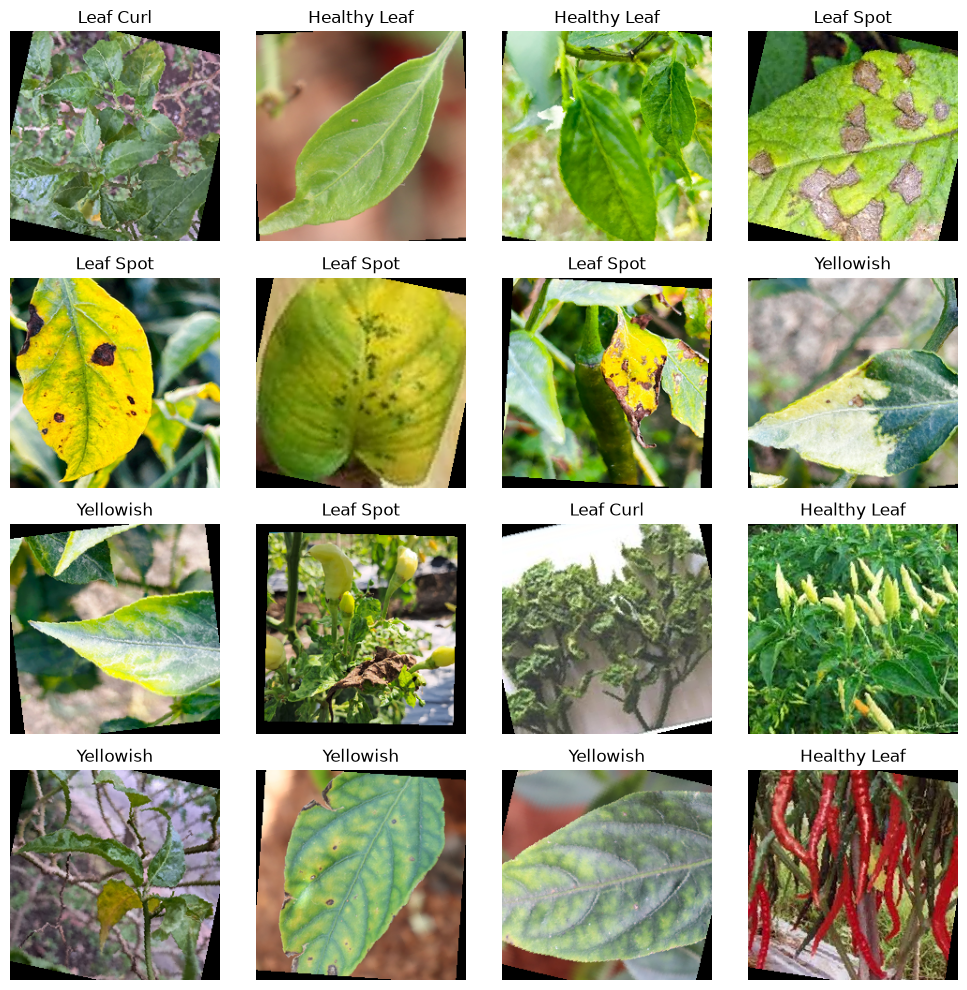

In [4]:
# Visualisasi 4x4 sampel train yang sudah diaugmentasi.
def denormalize(image_tensor) :
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    return (image_tensor.cpu() * std + mean).clamp(0, 1)

sample_indices = np.random.default_rng(seed).choice(len(train_dataset), size=min(16, len(train_dataset)), replace=False)
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for axis, sample_index in zip(axes.flat, sample_indices) :
    image, target = train_dataset[sample_index]
    axis.imshow(denormalize(image).permute(1, 2, 0))
    axis.set_title(CLASS_DISPLAY_NAMES.get(class_names[target], class_names[target]))
    axis.axis("off")
for axis in axes.flat[len(sample_indices):] :
    axis.axis("off")
plt.tight_layout()
plt.show()

# 4. CALLBACK

In [5]:
class EarlyStopping :
    def __init__(self, patience=PATIENCE) :
        self.patience = patience
        self.best_loss = float("inf")
        self.best_state_dict = None
        self.wait = 0

    def __call__(self, val_loss, model) :
        if val_loss < self.best_loss :
            self.best_loss = val_loss
            self.best_state_dict = copy.deepcopy(model.state_dict())
            self.wait = 0
            return False
        self.wait += 1
        return self.wait >= self.patience

    def restore(self, model) :
        if self.best_state_dict is None :
            raise RuntimeError("Belum ada state terbaik untuk dipulihkan.")
        model.load_state_dict(self.best_state_dict)

def save_checkpoint(model, path, **metadata) :
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save({"model_state_dict": model.state_dict(), **metadata}, path)
    return path

scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

# 5. FUNCTION EVALUASI

In [6]:
def evaluate_loss_accuracy(model, loader) :
    criterion = nn.CrossEntropyLoss()
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_items = 0
    with torch.no_grad() :
        for images, targets in loader :
            images, targets = images.to(device), targets.to(device)
            logits = model(images)
            total_loss += criterion(logits, targets).item() * targets.size(0)
            total_correct += (logits.argmax(dim=1) == targets).sum().item()
            total_items += targets.size(0)
    if total_items == 0 :
        raise ValueError("Loader evaluasi kosong.")
    return total_loss / total_items, total_correct / total_items

def predict_all(model, loader) :
    model.eval()
    y_true, y_pred, probs = [], [], []
    with torch.no_grad() :
        for images, targets in loader :
            logits = model(images.to(device))
            batch_probs = torch.softmax(logits, dim=1)
            y_true.extend(targets.numpy().tolist())
            y_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())
            probs.append(batch_probs.cpu().numpy())
    return np.asarray(y_true), np.asarray(y_pred), np.concatenate(probs, axis=0) if probs else np.empty((0, NUM_CLASSES))

def compute_metrics(y_true, y_pred, probs, loss) :
    del probs
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "loss": float(loss),
        "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "classification_report": classification_report(y_true, y_pred, output_dict=True, zero_division=0),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES)),
    }

def count_parameters(model) :
    return sum(parameter.numel() for parameter in model.parameters())

def model_size_mb(model) :
    temporary_path = None
    try :
        with tempfile.NamedTemporaryFile(suffix=".pth", delete=False) as temporary_file :
            temporary_path = temporary_file.name
        torch.save(model.state_dict(), temporary_path)
        return Path(temporary_path).stat().st_size / (1024 ** 2)
    finally :
        if temporary_path and Path(temporary_path).exists() :
            Path(temporary_path).unlink()

def measure_latency(model, warmup=20, runs=100) :
    model.eval()
    sample = torch.zeros(1, 3, IMG_SIZE[0], IMG_SIZE[1], device=device)
    timings = []
    with torch.no_grad() :
        for _ in range(warmup) :
            model(sample)
        if device.type == "cuda" :
            torch.cuda.synchronize()
        for _ in range(runs) :
            start = time.perf_counter()
            model(sample)
            if device.type == "cuda" :
                torch.cuda.synchronize()
            timings.append((time.perf_counter() - start) * 1000)
    return float(np.mean(timings)), float(np.std(timings))

# 6. MODEL

In [7]:
from torchvision import models

In [8]:
def make_head(input_features, dropout) :
    return nn.Sequential(
        nn.Dropout(p=dropout),
        nn.Linear(input_features, HIDDEN_DIM),
        nn.ReLU(),
        nn.Dropout(p=dropout),
        nn.Linear(HIDDEN_DIM, NUM_CLASSES),
    )

class FeatureBackbone(nn.Module) :
    def __init__(self, features) :
        super().__init__()
        self.features = features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.flatten = nn.Flatten()

    def forward(self, images) :
        return self.flatten(self.pool(self.features(images)))

class SingleBackboneModel(nn.Module) :
    def __init__(self, features, backbone_name, dropout) :
        super().__init__()
        self.features = features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = make_head(1280, dropout)
        self.backbone_name = backbone_name

    def forward(self, images) :
        features = self.pool(self.features(images)).flatten(1)
        return self.head(features)

class FusionModel(nn.Module) :
    def __init__(self, mobilenet_features, efficientnet_features, dropout) :
        super().__init__()
        self.mobilenet = FeatureBackbone(mobilenet_features)
        self.efficientnet = FeatureBackbone(efficientnet_features)
        self.head = make_head(2560, dropout)

    def forward(self, images) :
        mobilenet_features = self.mobilenet(images)
        efficientnet_features = self.efficientnet(images)
        fused_features = torch.cat((mobilenet_features, efficientnet_features), dim=1)
        return self.head(fused_features)


def build_mobilenet(dropout) :
    backbone = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
    assert len(backbone.features) == 19
    return SingleBackboneModel(backbone.features, "mobilenet", dropout).to(device)


def build_efficientnet(dropout) :
    backbone = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
    assert len(backbone.features) == 9
    return SingleBackboneModel(backbone.features, "efficientnet", dropout).to(device)


def build_hybrid(dropout) :
    mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
    efficientnet = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
    assert len(mobilenet.features) == 19
    assert len(efficientnet.features) == 9
    return FusionModel(mobilenet.features, efficientnet.features, dropout).to(device)


def _backbone_parts(model) :
    if isinstance(model, FusionModel) :
        return [("MobileNetV2", model.mobilenet), ("EfficientNetB0", model.efficientnet)]
    return [(model.backbone_name, model)]


def _last_conv_channels(module) :
    channels = [layer.out_channels for layer in module.modules() if isinstance(layer, nn.Conv2d)]
    if not channels :
        raise RuntimeError("Tidak menemukan Conv2d pada stage backbone.")
    return channels[-1]


def _stage_channel_table(model) :
    rows = []
    for backbone_name, backbone in _backbone_parts(model) :
        start_index = 14 if "mobilenet" in backbone_name.lower() else 6
        for index in range(start_index, len(backbone.features)) :
            rows.append({
                "Backbone": backbone_name,
                "Feature index": index,
                "Output channels": _last_conv_channels(backbone.features[index]),
            })
    return pd.DataFrame(rows)


def print_unfrozen_stage_channels(model) :
    table = _stage_channel_table(model)
    display(table)
    return table


def freeze_backbone(model) :
    for parameter in model.parameters() :
        parameter.requires_grad = False
    for parameter in model.head.parameters() :
        parameter.requires_grad = True
    return model


def unfreeze_last_stages(model) :
    freeze_backbone(model)
    for backbone_name, backbone in _backbone_parts(model) :
        start_index = 14 if "mobilenet" in backbone_name.lower() else 6
        for module in backbone.features[start_index:] :
            for parameter in module.parameters() :
                parameter.requires_grad = True
    print_unfrozen_stage_channels(model)
    return model


def set_train_mode(model, stage) :
    if stage not in (1, 2) :
        raise ValueError("stage harus 1 atau 2.")
    model.train()
    for _, backbone in _backbone_parts(model) :
        if stage == 1 :
            backbone.eval()
        else :
            for module in backbone.modules() :
                if module is backbone :
                    continue
                if any(parameter.requires_grad for parameter in module.parameters(recurse=False)) :
                    module.train()
                else :
                    module.eval()
    for module in model.modules() :
        if isinstance(module, nn.modules.batchnorm._BatchNorm) :
            module.eval()
    return model

mobilenet_model = build_mobilenet(BASE_CONFIG["dropout"])
efficientnet_model = build_efficientnet(BASE_CONFIG["dropout"])
hybrid_model = build_hybrid(BASE_CONFIG["dropout"])
print_unfrozen_stage_channels(hybrid_model)

,Backbone,Feature index,Output channels
0,MobileNetV2,14,160
1,MobileNetV2,15,160
2,MobileNetV2,16,160
3,MobileNetV2,17,320
4,MobileNetV2,18,1280
5,EfficientNetB0,6,192
6,EfficientNetB0,7,320
7,EfficientNetB0,8,1280


,Backbone,Feature index,Output channels
0,MobileNetV2,14,160
1,MobileNetV2,15,160
2,MobileNetV2,16,160
3,MobileNetV2,17,320
4,MobileNetV2,18,1280
5,EfficientNetB0,6,192
6,EfficientNetB0,7,320
7,EfficientNetB0,8,1280


In [9]:
def set_train_mode(model, stage) :
    if stage not in (1, 2) :
        raise ValueError("stage harus 1 atau 2.")
    model.train()
    for _, backbone in _backbone_parts(model) :
        if isinstance(model, FusionModel) :
            if stage == 1 :
                backbone.eval()
            else :
                backbone.train()
        elif stage == 1 :
            backbone.features.eval()
        else :
            backbone.features.train()
    for module in model.modules() :
        if isinstance(module, nn.modules.batchnorm._BatchNorm) :
            module.eval()
    return model

In [10]:
def _backbone_parts(model) :
    if isinstance(model, FusionModel) :
        return [("mobilenet", model.mobilenet), ("efficientnet", model.efficientnet)]
    return [(model.backbone_name, model)]


def _stage_start(backbone_name) :
    return 14 if backbone_name == "mobilenet" else 6


def print_unfrozen_stage_channels(model) :
    rows = []
    for backbone_name, backbone in _backbone_parts(model) :
        start_index = _stage_start(backbone_name)
        for index in range(start_index, len(backbone.features)) :
            rows.append({
                "Backbone": backbone_name,
                "Feature index": index,
                "Output channels": _last_conv_channels(backbone.features[index]),
            })
    table = pd.DataFrame(rows)
    display(table)
    return table


def unfreeze_last_stages(model) :
    freeze_backbone(model)
    for backbone_name, backbone in _backbone_parts(model) :
        start_index = _stage_start(backbone_name)
        for module in backbone.features[start_index:] :
            for parameter in module.parameters() :
                parameter.requires_grad = True
    print_unfrozen_stage_channels(model)
    return model

print_unfrozen_stage_channels(hybrid_model)

,Backbone,Feature index,Output channels
0,mobilenet,14,160
1,mobilenet,15,160
2,mobilenet,16,160
3,mobilenet,17,320
4,mobilenet,18,1280
5,efficientnet,6,192
6,efficientnet,7,320
7,efficientnet,8,1280


,Backbone,Feature index,Output channels
0,mobilenet,14,160
1,mobilenet,15,160
2,mobilenet,16,160
3,mobilenet,17,320
4,mobilenet,18,1280
5,efficientnet,6,192
6,efficientnet,7,320
7,efficientnet,8,1280


# 7. TRAINING FUNCTION (2 Tahap)

In [11]:
def train_one_epoch(model, loader, criterion, optimizer, scaler, stage, max_batches=None) :
    set_train_mode(model, stage)
    epoch_start = time.perf_counter()
    running_loss = 0.0
    running_correct = 0
    total_items = 0
    for batch_index, (images, targets) in enumerate(loader) :
        if max_batches is not None and batch_index >= max_batches :
            break
        images, targets = images.to(device, non_blocking=True), targets.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=device.type == "cuda") :
            logits = model(images)
            loss = criterion(logits, targets)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * targets.size(0)
        running_correct += (logits.argmax(dim=1) == targets).sum().item()
        total_items += targets.size(0)
    if total_items == 0 :
        raise ValueError("Loader training kosong atau max_batches terlalu kecil.")
    epoch_sec = time.perf_counter() - epoch_start
    return running_loss / total_items, running_correct / total_items, epoch_sec


def fit_stage(model, train_loader, val_loader, optimizer, max_epochs=STAGE_MAX_EPOCHS, patience=PATIENCE, stage=1, on_epoch_end=None) :
    criterion = nn.CrossEntropyLoss()
    early_stopping = EarlyStopping(patience=patience)
    history = []
    best_epoch = 0
    for epoch in range(1, max_epochs + 1) :
        train_loss, train_acc, epoch_sec = train_one_epoch(model, train_loader, criterion, optimizer, scaler, stage)
        val_loss, val_acc = evaluate_loss_accuracy(model, val_loader)
        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc,
            "epoch_sec": epoch_sec,
        }
        history.append(row)
        print(
            f"stage={stage} epoch={epoch}/{max_epochs} "
            f"train_loss={train_loss:.4f} val_loss={val_loss:.4f} "
            f"train_acc={train_acc:.4f} val_acc={val_acc:.4f} sec={epoch_sec:.2f}"
        )
        if on_epoch_end is not None :
            on_epoch_end(stage, epoch - 1, val_loss)
        if val_loss < early_stopping.best_loss :
            best_epoch = epoch
        # Early stopping memantau validation loss dan memulihkan bobot terbaik setelah loop.
        if early_stopping(val_loss, model) :
            print(f"Early stopping: stage {stage}, epoch {epoch}.")
            break
    early_stopping.restore(model)
    return history, best_epoch, len(history)


def build_optimizer(model, cfg, lr) :
    parameters = [parameter for parameter in model.parameters() if parameter.requires_grad]
    if not parameters :
        raise ValueError("Tidak ada parameter trainable untuk optimizer.")
    if cfg["optimizer"] == "Adam" :
        return torch.optim.Adam(parameters, lr=lr, weight_decay=cfg.get("weight_decay", 0.0))
    if cfg["optimizer"] == "AdamW" :
        return torch.optim.AdamW(parameters, lr=lr, weight_decay=cfg.get("weight_decay", 0.01))
    raise ValueError(f"Optimizer tidak didukung: {cfg['optimizer']}")


def train_model(model, cfg, seed, name, max_epochs=None, stage1_max_epochs=None, stage2_max_epochs=None, on_epoch_end=None) :
    seed_everything(seed)
    stage1_epochs = stage1_max_epochs if stage1_max_epochs is not None else (max_epochs or STAGE_MAX_EPOCHS)
    stage2_epochs = stage2_max_epochs if stage2_max_epochs is not None else (max_epochs or STAGE_MAX_EPOCHS)
    train_loader, validation_loader = make_loaders(cfg["batch_size"], seed)
    total_start = time.perf_counter()

    freeze_backbone(model)
    stage1_optimizer = build_optimizer(model, cfg, cfg["lr"])
    stage1_start = time.perf_counter()
    history_stage1, best_epoch_stage1, epochs_stage1 = fit_stage(
        model, train_loader, validation_loader, stage1_optimizer,
        max_epochs=stage1_epochs, patience=PATIENCE, stage=1, on_epoch_end=on_epoch_end,
    )
    stage1_sec = time.perf_counter() - stage1_start

    unfreeze_last_stages(model)
    stage2_optimizer = build_optimizer(model, cfg, cfg["lr"] / cfg.get("ft_lr_div", FINE_TUNE_LR_DIV))
    stage2_start = time.perf_counter()
    history_stage2, best_epoch_stage2, epochs_stage2 = fit_stage(
        model, train_loader, validation_loader, stage2_optimizer,
        max_epochs=stage2_epochs, patience=PATIENCE, stage=2, on_epoch_end=on_epoch_end,
    )
    stage2_sec = time.perf_counter() - stage2_start

    checkpoint_path = CHECKPOINT_DIR / f"{name}_seed{seed}.pth"
    save_checkpoint(
        model,
        checkpoint_path,
        name=name,
        seed=seed,
        config=cfg,
        best_epoch_stage1=best_epoch_stage1,
        best_epoch_stage2=best_epoch_stage2,
        history={"stage1": history_stage1, "stage2": history_stage2},
    )
    all_epoch_seconds = [row["epoch_sec"] for row in history_stage1 + history_stage2]
    timing = {
        "total_sec": time.perf_counter() - total_start,
        "stage1_sec": stage1_sec,
        "stage2_sec": stage2_sec,
        "epoch_sec_mean": float(np.mean(all_epoch_seconds)),
        "epochs_run": epochs_stage1 + epochs_stage2,
    }
    return model, {"stage1": history_stage1, "stage2": history_stage2}, timing

# 8. STUDY SETUP


In [12]:
import optuna
from optuna.trial import TrialState

TARGET = "hybrid"
EXPLORE_EXTRAS = False
N_TRIALS = 30
TIMEOUT_MIN = None
SEED = 42
RUN_TAG = time.strftime("%Y%m%d_%H%M%S")
OPTUNA_DIR = REPORT_DIR / "optuna"
OPTUNA_FIG_DIR = OPTUNA_DIR / "figures"
OPTUNA_DIR.mkdir(parents=True, exist_ok=True)
OPTUNA_FIG_DIR.mkdir(parents=True, exist_ok=True)
STUDY_DB = OPTUNA_DIR / "study.db"
STORAGE = f"sqlite:///{STUDY_DB.as_posix()}"
STUDY_NAME = f"{TARGET}_{RUN_TAG}"


def suggest_config(trial) :
    optimizer = trial.suggest_categorical("optimizer", ["Adam", "AdamW"])
    cfg = {
        "optimizer": optimizer,
        "lr": trial.suggest_float("lr", 1e-5, 1e-3, log=True),
        "dropout": trial.suggest_float("dropout", 0.2, 0.5, step=0.1),
        "batch_size": trial.suggest_categorical("batch_size", [16, 32]),
    }
    if EXPLORE_EXTRAS :
        cfg["weight_decay"] = trial.suggest_float("weight_decay", 1e-4, 1e-1, log=True) if optimizer == "AdamW" else 0.0
        cfg["ft_lr_div"] = trial.suggest_categorical("ft_lr_div", [5, 10, 20])
    else :
        cfg["weight_decay"] = 0.01 if optimizer == "AdamW" else 0.0
        cfg["ft_lr_div"] = FINE_TUNE_LR_DIV
    return cfg


def make_study(name, sampler_seed=SEED) :
    return optuna.create_study(
        study_name=name,
        storage=STORAGE,
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=sampler_seed, n_startup_trials=10),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=2),
        load_if_exists=True,
    )

study = make_study(STUDY_NAME)
if len(study.trials) == 0 :
    base_trial_config = dict(BASE_CONFIG)
    if EXPLORE_EXTRAS :
        base_trial_config["ft_lr_div"] = 10
    study.enqueue_trial(base_trial_config)
print(f"Study: {STUDY_NAME}; trial tersimpan: {len(study.trials)}")


[I 2026-10-18 20:18:55,090] A new study created in RDB with name: hybrid_20261018_201852


Study: hybrid_20261018_201852; trial tersimpan: 1


# 9. OBJECTIVE


In [13]:
def build_target_model(target, dropout) :
    builders = {
        "mobilenet": build_mobilenet,
        "efficientnet": build_efficientnet,
        "hybrid": build_hybrid,
    }
    if target not in builders :
        raise ValueError(f"TARGET tidak didukung: {target}")
    return builders[target](dropout)


def _validation_metrics(model, batch_size) :
    validation_loader = DataLoader(validation_dataset, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)
    val_loss, _ = evaluate_loss_accuracy(model, validation_loader)
    y_true, y_pred, probs = predict_all(model, validation_loader)
    metrics = compute_metrics(y_true, y_pred, probs, val_loss)
    return metrics


def _run_objective(trial, max_epochs_override=None, prune=True) :
    cfg = suggest_config(trial)
    seed_everything(SEED)
    model = None
    stage1_optimizer = None
    stage2_optimizer = None
    train_start = time.perf_counter()

    def on_epoch_end(stage, epoch, val_loss) :
        step = epoch if stage == 1 else 100 + epoch
        trial.report(val_loss, step=step)
        if prune and trial.should_prune() :
            raise optuna.TrialPruned()

    try :
        model = build_target_model(TARGET, cfg["dropout"])
        model, history, timing = train_model(
            model,
            cfg,
            seed=SEED,
            name=f"optuna_{TARGET}_trial{trial.number}",
            max_epochs=max_epochs_override,
            on_epoch_end=on_epoch_end,
        )
        metrics = _validation_metrics(model, cfg["batch_size"])
        trial.set_user_attr("val_acc", metrics["accuracy"])
        trial.set_user_attr("val_macro_f1", metrics["f1"])
        trial.set_user_attr("epochs_stage1", len(history["stage1"]))
        trial.set_user_attr("epochs_stage2", len(history["stage2"]))
        trial.set_user_attr("train_sec", timing["total_sec"] if timing else time.perf_counter() - train_start)
        return metrics["loss"]
    except torch.cuda.OutOfMemoryError :
        trial.set_user_attr("status", "oom")
        raise optuna.TrialPruned()
    finally :
        del stage1_optimizer, stage2_optimizer
        if model is not None :
            del model
        gc.collect()
        if torch.cuda.is_available() :
            torch.cuda.empty_cache()


def objective(trial) :
    return _run_objective(trial)

smoke_name = f"smoke_{TARGET}"
smoke_study = optuna.create_study(
    study_name=smoke_name,
    storage=STORAGE,
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=1),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=1, n_warmup_steps=1),
    load_if_exists=False,
)
try :
    smoke_study.optimize(lambda trial : _run_objective(trial, max_epochs_override=2), n_trials=2, gc_after_trial=True)
    print(f"Smoke test selesai: {len(smoke_study.trials)} trial.")
finally :
    optuna.delete_study(study_name=smoke_name, storage=STORAGE)
    print(f"Study smoke dihapus: {smoke_name}")


[I 2026-10-18 20:18:55,608] A new study created in RDB with name: smoke_hybrid


stage=1 epoch=1/2 train_loss=1.0520 val_loss=0.7094 train_acc=0.5905 val_acc=0.7745 sec=55.86
stage=1 epoch=2/2 train_loss=0.6550 val_loss=0.5502 train_acc=0.7607 val_acc=0.8085 sec=10.82


,Backbone,Feature index,Output channels
0,mobilenet,14,160
1,mobilenet,15,160
2,mobilenet,16,160
3,mobilenet,17,320
4,mobilenet,18,1280
5,efficientnet,6,192
6,efficientnet,7,320
7,efficientnet,8,1280


stage=2 epoch=1/2 train_loss=0.5258 val_loss=0.4300 train_acc=0.7962 val_acc=0.8638 sec=26.04
stage=2 epoch=2/2 train_loss=0.4062 val_loss=0.3672 train_acc=0.8571 val_acc=0.8809 sec=12.34


[I 2026-10-18 20:20:58,920] Trial 0 finished with value: 0.36724609922855456 and parameters: {'optimizer': 'AdamW', 'lr': 0.000291063591313307, 'dropout': 0.4, 'batch_size': 16}. Best is trial 0 with value: 0.36724609922855456.


stage=1 epoch=1/2 train_loss=0.9864 val_loss=0.5946 train_acc=0.5823 val_acc=0.7957 sec=8.48
stage=1 epoch=2/2 train_loss=0.6391 val_loss=0.4998 train_acc=0.7489 val_acc=0.8085 sec=6.33


,Backbone,Feature index,Output channels
0,mobilenet,14,160
1,mobilenet,15,160
2,mobilenet,16,160
3,mobilenet,17,320
4,mobilenet,18,1280
5,efficientnet,6,192
6,efficientnet,7,320
7,efficientnet,8,1280


stage=2 epoch=1/2 train_loss=0.5566 val_loss=0.3770 train_acc=0.7898 val_acc=0.8809 sec=11.42
stage=2 epoch=2/2 train_loss=0.4054 val_loss=0.3549 train_acc=0.8480 val_acc=0.8723 sec=13.35


[I 2026-10-18 20:21:52,176] Trial 1 finished with value: 0.35491283434502624 and parameters: {'optimizer': 'AdamW', 'lr': 0.0007386307580366311, 'dropout': 0.5, 'batch_size': 16}. Best is trial 1 with value: 0.35491283434502624.


Smoke test selesai: 2 trial.
Study smoke dihapus: smoke_hybrid


# 10. RUN STUDY


In [14]:
study.optimize(
    objective,
    n_trials=N_TRIALS,
    timeout=TIMEOUT_MIN * 60 if TIMEOUT_MIN is not None else None,
    gc_after_trial=True,
)

state_counts = {
    state.name: sum(trial.state == state for trial in study.trials)
    for state in (TrialState.COMPLETE, TrialState.PRUNED)
}
print("Jumlah trial:", state_counts)
complete_trials = [trial for trial in study.trials if trial.state == TrialState.COMPLETE]
for trial in sorted(complete_trials, key=lambda item : item.value)[:10] :
    print({"number": trial.number, "params": trial.params, "val_loss": trial.value, "val_macro_f1": trial.user_attrs.get("val_macro_f1")})
trial_zero = next((trial for trial in study.trials if trial.number == 0), None)
if trial_zero is not None :
    print("Trial 0 baseline:", {"state": trial_zero.state.name, "params": trial_zero.params, "val_loss": trial_zero.value, "val_macro_f1": trial_zero.user_attrs.get("val_macro_f1")})


stage=1 epoch=1/50 train_loss=1.2796 val_loss=1.1140 train_acc=0.4586 val_acc=0.6809 sec=10.58
stage=1 epoch=2/50 train_loss=1.0212 val_loss=0.8666 train_acc=0.6633 val_acc=0.7362 sec=10.78
stage=1 epoch=3/50 train_loss=0.8465 val_loss=0.7203 train_acc=0.7052 val_acc=0.7787 sec=10.42
stage=1 epoch=4/50 train_loss=0.7106 val_loss=0.6450 train_acc=0.7571 val_acc=0.7957 sec=10.50
stage=1 epoch=5/50 train_loss=0.6624 val_loss=0.5841 train_acc=0.7889 val_acc=0.8128 sec=10.39
stage=1 epoch=6/50 train_loss=0.6066 val_loss=0.5418 train_acc=0.7889 val_acc=0.8298 sec=10.72
stage=1 epoch=7/50 train_loss=0.5557 val_loss=0.5161 train_acc=0.8198 val_acc=0.8298 sec=10.59
stage=1 epoch=8/50 train_loss=0.5237 val_loss=0.4999 train_acc=0.8144 val_acc=0.8426 sec=10.46
stage=1 epoch=9/50 train_loss=0.4925 val_loss=0.4697 train_acc=0.8198 val_acc=0.8426 sec=10.79
stage=1 epoch=10/50 train_loss=0.4794 val_loss=0.4539 train_acc=0.8171 val_acc=0.8426 sec=10.61
stage=1 epoch=11/50 train_loss=0.4477 val_loss=0.

,Backbone,Feature index,Output channels
0,mobilenet,14,160
1,mobilenet,15,160
2,mobilenet,16,160
3,mobilenet,17,320
4,mobilenet,18,1280
5,efficientnet,6,192
6,efficientnet,7,320
7,efficientnet,8,1280


stage=2 epoch=1/50 train_loss=0.2972 val_loss=0.3279 train_acc=0.8954 val_acc=0.8766 sec=7.87
stage=2 epoch=2/50 train_loss=0.2946 val_loss=0.3403 train_acc=0.8981 val_acc=0.8638 sec=7.47
stage=2 epoch=3/50 train_loss=0.2492 val_loss=0.3206 train_acc=0.9090 val_acc=0.8723 sec=8.08
stage=2 epoch=4/50 train_loss=0.2409 val_loss=0.3168 train_acc=0.9108 val_acc=0.8766 sec=7.61
stage=2 epoch=5/50 train_loss=0.2344 val_loss=0.3024 train_acc=0.9108 val_acc=0.8851 sec=7.15
stage=2 epoch=6/50 train_loss=0.2199 val_loss=0.3124 train_acc=0.9154 val_acc=0.8723 sec=7.97
stage=2 epoch=7/50 train_loss=0.2118 val_loss=0.3292 train_acc=0.9254 val_acc=0.8596 sec=7.21
stage=2 epoch=8/50 train_loss=0.2100 val_loss=0.2875 train_acc=0.9227 val_acc=0.8894 sec=8.02
stage=2 epoch=9/50 train_loss=0.1918 val_loss=0.2846 train_acc=0.9236 val_acc=0.8936 sec=7.98
stage=2 epoch=10/50 train_loss=0.1701 val_loss=0.2936 train_acc=0.9318 val_acc=0.8851 sec=7.77
stage=2 epoch=11/50 train_loss=0.1766 val_loss=0.3168 train

[I 2026-10-18 20:30:45,125] Trial 0 finished with value: 0.2845640684061862 and parameters: {'optimizer': 'Adam', 'lr': 0.0001, 'dropout': 0.5, 'batch_size': 16}. Best is trial 0 with value: 0.2845640684061862.


stage=1 epoch=1/50 train_loss=1.0520 val_loss=0.7094 train_acc=0.5905 val_acc=0.7745 sec=6.48
stage=1 epoch=2/50 train_loss=0.6550 val_loss=0.5502 train_acc=0.7607 val_acc=0.8085 sec=5.76
stage=1 epoch=3/50 train_loss=0.5442 val_loss=0.4693 train_acc=0.8107 val_acc=0.8511 sec=6.28
stage=1 epoch=4/50 train_loss=0.4435 val_loss=0.4314 train_acc=0.8462 val_acc=0.8638 sec=5.67
stage=1 epoch=5/50 train_loss=0.4167 val_loss=0.5067 train_acc=0.8471 val_acc=0.8128 sec=5.71
stage=1 epoch=6/50 train_loss=0.3899 val_loss=0.4048 train_acc=0.8626 val_acc=0.8511 sec=6.09
stage=1 epoch=7/50 train_loss=0.3667 val_loss=0.4082 train_acc=0.8662 val_acc=0.8511 sec=5.62
stage=1 epoch=8/50 train_loss=0.3207 val_loss=0.3772 train_acc=0.8790 val_acc=0.8383 sec=5.79
stage=1 epoch=9/50 train_loss=0.2984 val_loss=0.3626 train_acc=0.8844 val_acc=0.8511 sec=6.42
stage=1 epoch=10/50 train_loss=0.2901 val_loss=0.3458 train_acc=0.8954 val_acc=0.8723 sec=5.85
stage=1 epoch=11/50 train_loss=0.2606 val_loss=0.3673 train

...

stage=2 epoch=1/50 train_loss=0.2276 val_loss=0.4018 train_acc=0.9181 val_acc=0.8596 sec=6.95


[I 2026-10-18 22:09:59,307] Trial 28 pruned. 


stage=1 epoch=1/50 train_loss=1.1652 val_loss=0.8797 train_acc=0.5314 val_acc=0.7319 sec=6.01
stage=1 epoch=2/50 train_loss=0.7680 val_loss=0.6410 train_acc=0.7407 val_acc=0.7830 sec=6.12
stage=1 epoch=3/50 train_loss=0.6255 val_loss=0.5490 train_acc=0.7743 val_acc=0.8213 sec=6.16


[I 2026-10-18 22:10:22,860] Trial 29 pruned. 


Jumlah trial: {'COMPLETE': 15, 'PRUNED': 15}
{'number': 11, 'params': {'optimizer': 'AdamW', 'lr': 0.0006704257969575548, 'dropout': 0.4, 'batch_size': 16}, 'val_loss': 0.20845637999950573, 'val_macro_f1': 0.9233370001171858}
{'number': 16, 'params': {'optimizer': 'AdamW', 'lr': 0.0003874431756033743, 'dropout': 0.5, 'batch_size': 16}, 'val_loss': 0.22559138612544283, 'val_macro_f1': 0.9146662245800176}
{'number': 1, 'params': {'optimizer': 'AdamW', 'lr': 0.000291063591313307, 'dropout': 0.4, 'batch_size': 16}, 'val_loss': 0.24278108052750852, 'val_macro_f1': 0.8933792377734604}
{'number': 23, 'params': {'optimizer': 'Adam', 'lr': 0.0004160617933755991, 'dropout': 0.4, 'batch_size': 16}, 'val_loss': 0.2443518707409818, 'val_macro_f1': 0.9141655844155844}
{'number': 21, 'params': {'optimizer': 'AdamW', 'lr': 0.00045127924343686074, 'dropout': 0.5, 'batch_size': 16}, 'val_loss': 0.2511052993383813, 'val_macro_f1': 0.9063088512241054}
{'number': 13, 'params': {'optimizer': 'Adam', 'lr': 0

# 11. KONFIRMASI SEED


In [15]:
CONFIRM_TOP_K = 3
CONFIRM_SEEDS = [43, 44]

complete_trials = [trial for trial in study.trials if trial.state == TrialState.COMPLETE]
selected_trials = sorted(complete_trials, key=lambda item : item.value)[:CONFIRM_TOP_K]
trial_zero = next((trial for trial in complete_trials if trial.number == 0), None)
if trial_zero is not None and trial_zero not in selected_trials :
    selected_trials.append(trial_zero)

confirmation_rows = []
for trial in selected_trials :
    cfg = dict(trial.params)
    cfg["weight_decay"] = cfg.get("weight_decay", 0.01 if cfg["optimizer"] == "AdamW" else 0.0)
    cfg["ft_lr_div"] = cfg.get("ft_lr_div", FINE_TUNE_LR_DIV)
    original_metrics = {
        "val_loss": trial.value,
        "val_macro_f1": trial.user_attrs.get("val_macro_f1"),
        "seed": SEED,
    }
    confirmation_rows.append({"trial": trial.number, **cfg, **original_metrics})
    for confirm_seed in CONFIRM_SEEDS :
        seed_everything(confirm_seed)
        model = build_target_model(TARGET, cfg["dropout"])
        model, _, _ = train_model(
            model,
            cfg,
            seed=confirm_seed,
            name=f"confirm_{TARGET}_trial{trial.number}",
        )
        metrics = _validation_metrics(model, cfg["batch_size"])
        confirmation_rows.append({
            "trial": trial.number,
            **cfg,
            "val_loss": metrics["loss"],
            "val_macro_f1": metrics["f1"],
            "seed": confirm_seed,
        })
        del model
        gc.collect()
        if torch.cuda.is_available() :
            torch.cuda.empty_cache()

confirm_frame = pd.DataFrame(confirmation_rows)
summary_rows = []
for trial_number, group in confirm_frame.groupby("trial") :
    summary_rows.append({
        "trial": trial_number,
        "val_loss_mean_std": f"{group['val_loss'].mean():.6f} ± {group['val_loss'].std(ddof=0):.6f}",
        "val_macro_f1_mean_std": f"{group['val_macro_f1'].mean():.6f} ± {group['val_macro_f1'].std(ddof=0):.6f}",
        "seeds": ",".join(str(seed) for seed in group["seed"]),
    })
summary_frame = pd.DataFrame(summary_rows)
display(summary_frame)
validation_size = len(validation_dataset)
print(f"Selisih lebih kecil dari std dianggap noise. Validation = {validation_size} citra, 1 citra = {100 / validation_size:.2f}%.")
confirm_frame.to_csv(OPTUNA_DIR / "confirm.csv", index=False)


stage=1 epoch=1/50 train_loss=0.9220 val_loss=0.5776 train_acc=0.6224 val_acc=0.8085 sec=5.79
stage=1 epoch=2/50 train_loss=0.5498 val_loss=0.4771 train_acc=0.7862 val_acc=0.8468 sec=5.71
stage=1 epoch=3/50 train_loss=0.4571 val_loss=0.4042 train_acc=0.8408 val_acc=0.8553 sec=6.27
stage=1 epoch=4/50 train_loss=0.4267 val_loss=0.3955 train_acc=0.8408 val_acc=0.8596 sec=5.62
stage=1 epoch=5/50 train_loss=0.3528 val_loss=0.4364 train_acc=0.8653 val_acc=0.8213 sec=6.55
stage=1 epoch=6/50 train_loss=0.3129 val_loss=0.3836 train_acc=0.8726 val_acc=0.8553 sec=6.35
stage=1 epoch=7/50 train_loss=0.2925 val_loss=0.4062 train_acc=0.8881 val_acc=0.8468 sec=5.45
stage=1 epoch=8/50 train_loss=0.2946 val_loss=0.3707 train_acc=0.8917 val_acc=0.8511 sec=5.51
stage=1 epoch=9/50 train_loss=0.2723 val_loss=0.4083 train_acc=0.8990 val_acc=0.8383 sec=5.55
stage=1 epoch=10/50 train_loss=0.2300 val_loss=0.3804 train_acc=0.9072 val_acc=0.8596 sec=5.45
stage=1 epoch=11/50 train_loss=0.2008 val_loss=0.3566 train

,Backbone,Feature index,Output channels
0,mobilenet,14,160
1,mobilenet,15,160
2,mobilenet,16,160
3,mobilenet,17,320
4,mobilenet,18,1280
5,efficientnet,6,192
6,efficientnet,7,320
7,efficientnet,8,1280


stage=2 epoch=1/50 train_loss=0.2173 val_loss=0.4628 train_acc=0.9108 val_acc=0.8426 sec=6.25
stage=2 epoch=2/50 train_loss=0.1640 val_loss=0.4327 train_acc=0.9436 val_acc=0.8426 sec=6.27
stage=2 epoch=3/50 train_loss=0.1684 val_loss=0.4970 train_acc=0.9427 val_acc=0.8298 sec=6.37
stage=2 epoch=4/50 train_loss=0.1517 val_loss=0.3776 train_acc=0.9381 val_acc=0.8638 sec=6.30
stage=2 epoch=5/50 train_loss=0.1232 val_loss=0.3567 train_acc=0.9600 val_acc=0.8809 sec=6.26
stage=2 epoch=6/50 train_loss=0.1089 val_loss=0.2835 train_acc=0.9609 val_acc=0.9149 sec=6.24
stage=2 epoch=7/50 train_loss=0.0910 val_loss=0.3659 train_acc=0.9672 val_acc=0.8723 sec=6.23
stage=2 epoch=8/50 train_loss=0.0745 val_loss=0.3665 train_acc=0.9736 val_acc=0.8809 sec=6.44
stage=2 epoch=9/50 train_loss=0.0760 val_loss=0.3585 train_acc=0.9727 val_acc=0.8894 sec=6.44
stage=2 epoch=10/50 train_loss=0.0872 val_loss=0.3347 train_acc=0.9682 val_acc=0.8936 sec=6.25
stage=2 epoch=11/50 train_loss=0.0901 val_loss=0.3806 train

,Backbone,Feature index,Output channels
0,mobilenet,14,160
1,mobilenet,15,160
2,mobilenet,16,160
3,mobilenet,17,320
4,mobilenet,18,1280
5,efficientnet,6,192
6,efficientnet,7,320
7,efficientnet,8,1280


stage=2 epoch=1/50 train_loss=0.2933 val_loss=0.4141 train_acc=0.8899 val_acc=0.8298 sec=6.47
stage=2 epoch=2/50 train_loss=0.1995 val_loss=0.3136 train_acc=0.9254 val_acc=0.8851 sec=6.23
stage=2 epoch=3/50 train_loss=0.2040 val_loss=0.2874 train_acc=0.9318 val_acc=0.8809 sec=6.26
stage=2 epoch=4/50 train_loss=0.1511 val_loss=0.2786 train_acc=0.9500 val_acc=0.9149 sec=6.28
stage=2 epoch=5/50 train_loss=0.1220 val_loss=0.3158 train_acc=0.9536 val_acc=0.8723 sec=6.34
stage=2 epoch=6/50 train_loss=0.1229 val_loss=0.2505 train_acc=0.9545 val_acc=0.9064 sec=6.34
stage=2 epoch=7/50 train_loss=0.0930 val_loss=0.3145 train_acc=0.9672 val_acc=0.9021 sec=6.37
stage=2 epoch=8/50 train_loss=0.1029 val_loss=0.3160 train_acc=0.9618 val_acc=0.8851 sec=6.32
stage=2 epoch=9/50 train_loss=0.0995 val_loss=0.2530 train_acc=0.9654 val_acc=0.9234 sec=6.35
stage=2 epoch=10/50 train_loss=0.1144 val_loss=0.2648 train_acc=0.9572 val_acc=0.8979 sec=6.38
stage=2 epoch=11/50 train_loss=0.0958 val_loss=0.3046 train

...

stage=2 epoch=1/50 train_loss=0.3098 val_loss=0.3302 train_acc=0.8826 val_acc=0.8723 sec=9.02
stage=2 epoch=2/50 train_loss=0.2548 val_loss=0.3129 train_acc=0.9035 val_acc=0.8723 sec=9.09
stage=2 epoch=3/50 train_loss=0.2572 val_loss=0.3249 train_acc=0.8999 val_acc=0.8723 sec=6.72
stage=2 epoch=4/50 train_loss=0.2341 val_loss=0.3285 train_acc=0.9136 val_acc=0.8766 sec=6.76
stage=2 epoch=5/50 train_loss=0.2148 val_loss=0.3185 train_acc=0.9190 val_acc=0.8766 sec=6.73
stage=2 epoch=6/50 train_loss=0.1891 val_loss=0.3168 train_acc=0.9345 val_acc=0.8681 sec=6.66
stage=2 epoch=7/50 train_loss=0.2146 val_loss=0.3113 train_acc=0.9299 val_acc=0.8723 sec=6.72
stage=2 epoch=8/50 train_loss=0.1766 val_loss=0.2936 train_acc=0.9363 val_acc=0.8766 sec=6.72
stage=2 epoch=9/50 train_loss=0.2211 val_loss=0.2866 train_acc=0.9254 val_acc=0.8809 sec=6.66
stage=2 epoch=10/50 train_loss=0.1742 val_loss=0.2830 train_acc=0.9372 val_acc=0.8766 sec=6.69
stage=2 epoch=11/50 train_loss=0.1837 val_loss=0.3150 train

,Backbone,Feature index,Output channels
0,mobilenet,14,160
1,mobilenet,15,160
2,mobilenet,16,160
3,mobilenet,17,320
4,mobilenet,18,1280
5,efficientnet,6,192
6,efficientnet,7,320
7,efficientnet,8,1280


stage=2 epoch=1/50 train_loss=0.3149 val_loss=0.3560 train_acc=0.8817 val_acc=0.8723 sec=7.22
stage=2 epoch=2/50 train_loss=0.2922 val_loss=0.3275 train_acc=0.8981 val_acc=0.8723 sec=7.18
stage=2 epoch=3/50 train_loss=0.3084 val_loss=0.3311 train_acc=0.8935 val_acc=0.8766 sec=6.86
stage=2 epoch=4/50 train_loss=0.2671 val_loss=0.3366 train_acc=0.8981 val_acc=0.8681 sec=6.59
stage=2 epoch=5/50 train_loss=0.2297 val_loss=0.3257 train_acc=0.9063 val_acc=0.8723 sec=6.72
stage=2 epoch=6/50 train_loss=0.2189 val_loss=0.3436 train_acc=0.9236 val_acc=0.8766 sec=6.48
stage=2 epoch=7/50 train_loss=0.2108 val_loss=0.3240 train_acc=0.9254 val_acc=0.8809 sec=6.41
stage=2 epoch=8/50 train_loss=0.2150 val_loss=0.3221 train_acc=0.9290 val_acc=0.8681 sec=6.39
stage=2 epoch=9/50 train_loss=0.1918 val_loss=0.2985 train_acc=0.9299 val_acc=0.8936 sec=6.78
stage=2 epoch=10/50 train_loss=0.2043 val_loss=0.2915 train_acc=0.9190 val_acc=0.8936 sec=6.41
stage=2 epoch=11/50 train_loss=0.1841 val_loss=0.2883 train

,trial,val_loss_mean_std,val_macro_f1_mean_std,seeds
0,0,0.274134 ± 0.013758,0.887768 ± 0.011250,"42,43,44"
1,1,0.251542 ± 0.009411,0.903088 ± 0.013978,"42,43,44"
2,11,0.247494 ± 0.030716,0.914667 ± 0.007170,"42,43,44"
3,16,0.234274 ± 0.016265,0.907489 ± 0.007025,"42,43,44"


Selisih lebih kecil dari std dianggap noise. Validation = 235 citra, 1 citra = 0.43%.


# 12. ANALISIS


In [18]:
trials_frame = study.trials_dataframe(attrs=("number", "value", "datetime_start", "datetime_complete", "duration", "state", "params", "user_attrs"))
trials_frame.to_csv(OPTUNA_DIR / "trials.csv", index=False)

from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances, plot_slice

plot_optimization_history(study)
figure = plt.gcf()
figure.savefig(OPTUNA_FIG_DIR / "optimization_history.png", dpi=200, bbox_inches="tight")
plt.close(figure)
try :
    plot_param_importances(study)
    figure = plt.gcf()
    figure.savefig(OPTUNA_FIG_DIR / "param_importances.png", dpi=200, bbox_inches="tight")
    plt.close(figure)
except Exception as error :
    print(f"Plot parameter importance dilewati: {error}")
plot_slice(study)
figure = plt.gcf()
figure.savefig(OPTUNA_FIG_DIR / "slice.png", dpi=200, bbox_inches="tight")
plt.close(figure)


C:\Users\rifqi\AppData\Local\Temp\ipykernel_18236\3686263654.py:6: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study)
C:\Users\rifqi\AppData\Local\Temp\ipykernel_18236\3686263654.py:11: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study)
C:\Users\rifqi\AppData\Local\Temp\ipykernel_18236\3686263654.py:17: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  plot_slice(study)
